Nama    : Candra Sya'bana Putra Gunadi <br>
NIM     : 60324042 <br>
Kelas   : Visualisasi Data (A) <br>

## PRAKTIKUM

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)
df["age"] = df["age"].fillna(df["age"].mean())
df = df.dropna(subset=["embarked"])
df = df.drop_duplicates()

sns.set_theme(style="whitegrid")
print("Data siap divisualisasikan:", df.shape)

Data siap divisualisasikan: (782, 15)


Histogram dan KDE

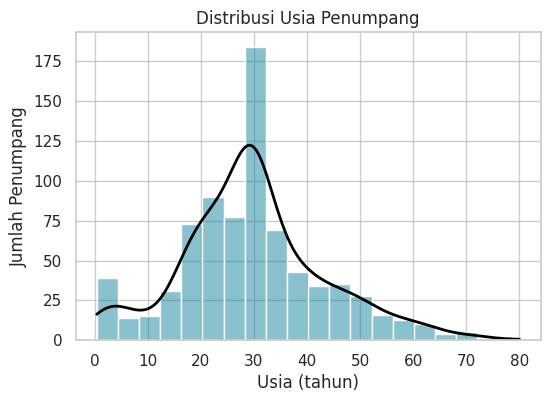

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="#16849E",
    ax=ax
)

for line in ax.lines:
    line.set_color("black")
    line.set_linewidth(2)

ax.set_title("Distribusi Usia Penumpang")
ax.set_xlabel("Usia (tahun)")
ax.set_ylabel("Jumlah Penumpang")

plt.show()

Membandingkan Dua Distribusi dengan hue

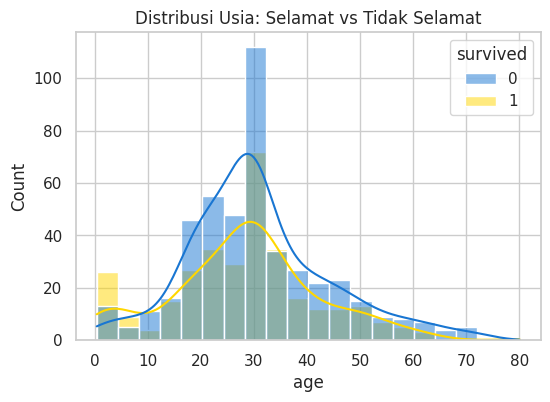

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(
    data=df,
    x="age",
    hue="survived",
    bins=20,
    kde=True,
    palette={0: "#1976D2", 1: "#FFD700"},
    ax=ax
)

ax.set_title("Distribusi Usia: Selamat vs Tidak Selamat")
plt.show()

Boxplot

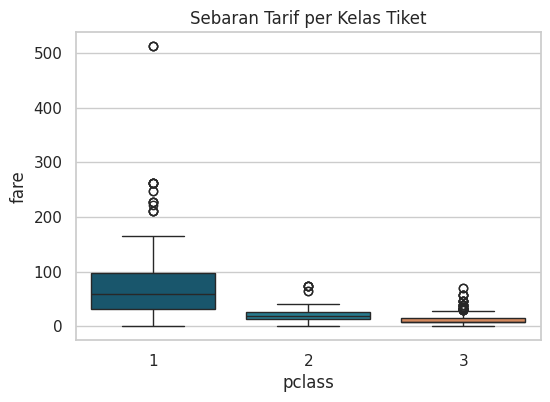

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="pclass", y="fare",
      hue="pclass", legend=False,
      palette=["#0B5D7A", "#16849E", "#E8834A"], ax=ax)
ax.set_title("Sebaran Tarif per Kelas Tiket")
plt.show()

Violin Plot

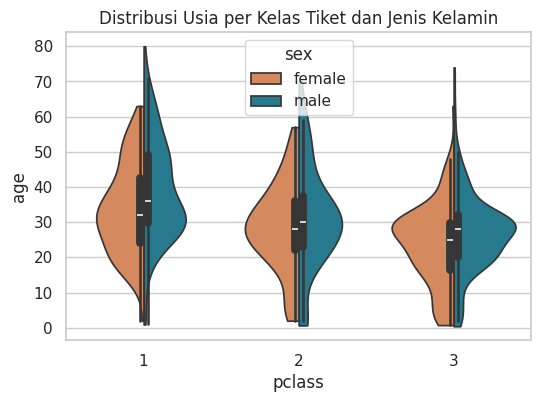

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(data=df, x="pclass", y="age",
        hue="sex", split=True, cut=0,
        palette={"female": "#E8834A", "male": "#16849E"}, ax=ax)
ax.set_title("Distribusi Usia per Kelas Tiket dan Jenis Kelamin")
plt.show()

Heatmap Korelasi

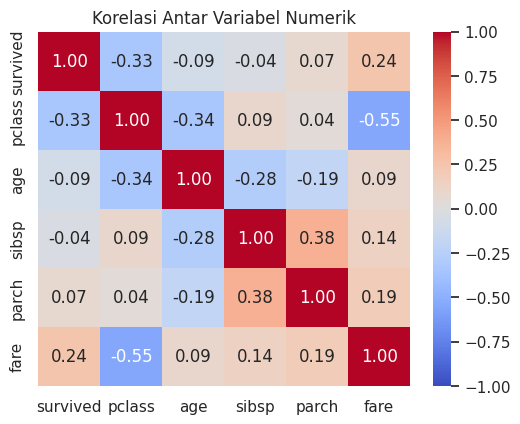

In [ ]:
kolom = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
korelasi = df[kolom].corr()

fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(korelasi, annot=True, fmt=".2f",
      cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi Antar Variabel Numerik")
plt.show()

Pairplot

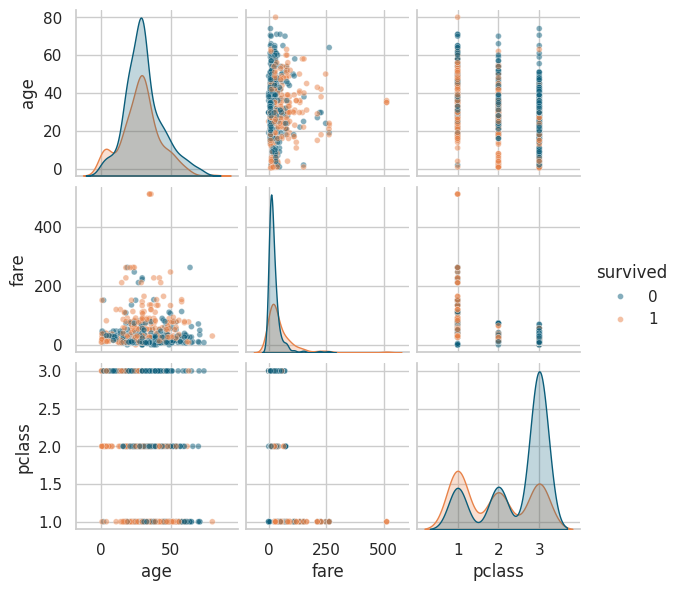

In [ ]:
g = sns.pairplot(
  df[["survived", "age", "fare", "pclass"]],
  hue="survived",
  palette={0: "#0B5D7A", 1: "#E8834A"},
  height=2.0, plot_kws={"alpha": 0.5, "s": 18})
plt.show()

**Proyek Mini: Menjawab Tiga Pertanyaan dengan Data**

1. Distribusi tarif: tidak merata dan menjulur ke kanan (nilai skewness = 4.79). Sebagian besar penumpang membeli tiket dengan harga di bawah $35, sementara hanya segelintir orang yang membayar dengan tarif yang sangat mahal.

2. Rentang usia yang paling bervariasi ditemukan pada penumpang kelas 1 (dengan standar deviasi sebesar 14.80).

3. Hubungan (korelasi) positif tertinggi dengan keselamatan penumpang ada pada variabel fare/tarif (r = 0.26), yang disusul oleh variabel parch (r = 0.08). Catatan: korelasi tidak membuktikan sebab-akibat karena keselamatan seseorang juga sangat dipengaruhi oleh variabel eksternal lainnya, seperti posisi kamar di kapal, prioritas penyelamatan, atau akses ke sekoci.

## Ringkasan Visualisasi Statistik

1. **Distribusi Usia (Histogram & KDE):** Visualisasi menunjukkan sebaran usia penumpang. Perlu dicatat bahwa lonjakan tajam pada usia sekitar 30 tahun terjadi akibat proses imputasi nilai kosong (*missing values*) menggunakan nilai rata-rata (*mean*), sehingga tidak merepresentasikan pola alami data asli.
2. **Perbandingan Karakteristik (Boxplot & Violin Plot):** Penggunaan grafik *boxplot* dan *violin plot* sangat membantu untuk membandingkan sebaran variabel numerik (seperti tarif tiket dan usia) berdasarkan kategori tertentu, seperti kelas tiket (*pclass*) dan jenis kelamin (*gender*).
3. **Analisis Hubungan (Heatmap Korelasi):** Berdasarkan visualisasi korelasi, hubungan linier terkuat ditemukan antara tarif tiket (*fare*) dan kelas tiket (*pclass*) dengan koefisien sebesar -0.55. Ingatlah bahwa nilai korelasi ini hanya menunjukkan hubungan statistik dan tidak membuktikan hubungan sebab-akibat langsung.
4. **Eksplorasi Awal (Pairplot):** Penggunaan *pairplot* sangat efektif untuk melakukan eksplorasi data secara cepat di awal guna melihat hubungan antar berbagai variabel numerik secara simultan sebelum melakukan analisis yang lebih mendalam.

## LATIHAN MANDIRI

Latihan 1

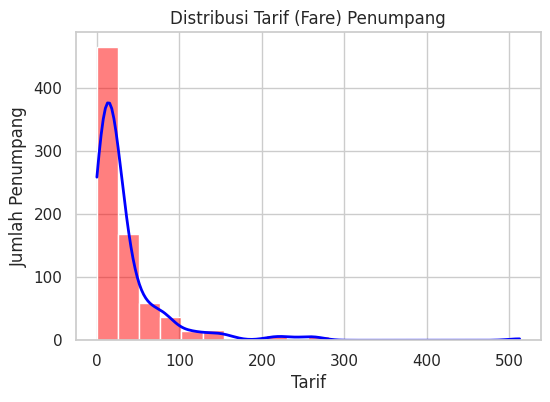

Nilai Skewness Kolom Fare : 4.58
Nilai Skewness Kolom Age  : 0.40

Variabel yang lebih condong (skewed) adalah: fare


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(
    data=df,
    x="fare",
    bins=20,
    kde=True,
    color="red",
    ax=ax
)

for line in ax.lines:
    line.set_color("blue")
    line.set_linewidth(2)

ax.set_title("Distribusi Tarif (Fare) Penumpang")
ax.set_xlabel("Tarif")
ax.set_ylabel("Jumlah Penumpang")
plt.show()

skew_fare = df["fare"].skew()
skew_age = df["age"].skew()

print(f"Nilai Skewness Kolom Fare : {skew_fare:.2f}")
print(f"Nilai Skewness Kolom Age  : {skew_age:.2f}")

if abs(skew_fare) > abs(skew_age):
    print("\nVariabel yang lebih condong (skewed) adalah: fare")
else:
    print("\nVariabel yang lebih condong (skewed) adalah: age")

Latihan 2

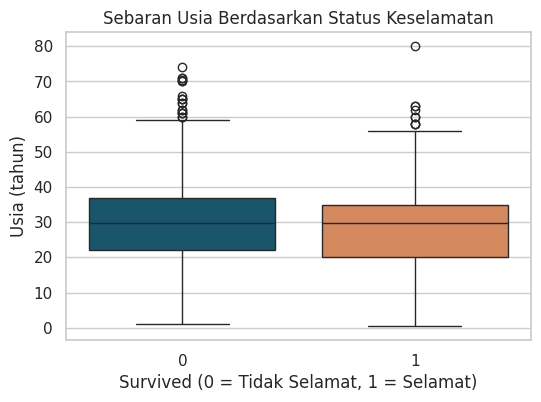

Median Usia (Tidak Selamat) : 29.7 tahun
Median Usia (Selamat)       : 29.7 tahun


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="survived", y="age", hue="survived", legend=False,
            palette={0: "#0B5D7A", 1: "#E8834A"}, ax=ax)
ax.set_title("Sebaran Usia Berdasarkan Status Keselamatan")
ax.set_xlabel("Survived (0 = Tidak Selamat, 1 = Selamat)")
ax.set_ylabel("Usia (tahun)")
plt.show()

median_tidak_selamat = df[df["survived"] == 0]["age"].median()
median_selamat = df[df["survived"] == 1]["age"].median()

print(f"Median Usia (Tidak Selamat) : {median_tidak_selamat:.1f} tahun")
print(f"Median Usia (Selamat)       : {median_selamat:.1f} tahun")

Latihan 3

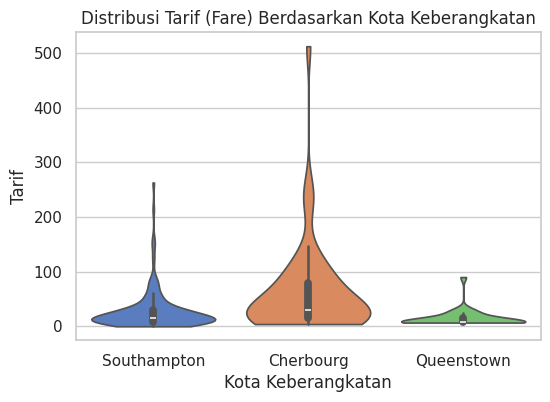

Standar Deviasi Tarif per Kota:
embark_town
Cherbourg      86.19
Queenstown     15.94
Southampton    37.39
Name: fare, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(data=df, x="embark_town", y="fare", hue="embark_town", legend=False, cut=0, palette="muted", ax=ax)
ax.set_title("Distribusi Tarif (Fare) Berdasarkan Kota Keberangkatan")
ax.set_xlabel("Kota Keberangkatan")
ax.set_ylabel("Tarif")
plt.show()

variasi_tarif = df.groupby("embark_town")["fare"].std()
print("Standar Deviasi Tarif per Kota:")
print(variasi_tarif.round(2))

Latihan 4

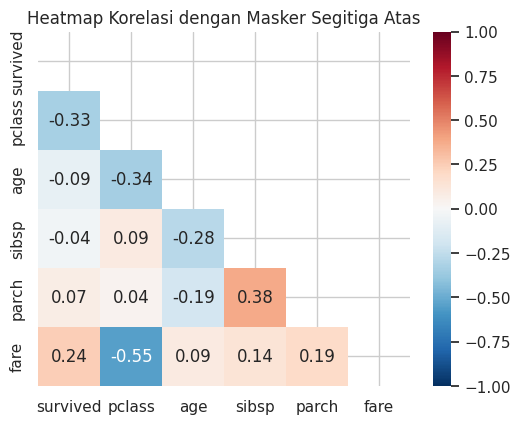

In [ ]:
kolom = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
korelasi = df[kolom].corr()

mask = np.triu(np.ones_like(korelasi, dtype=bool))

fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(korelasi, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Heatmap Korelasi dengan Masker Segitiga Atas")
plt.show()

Latihan 5

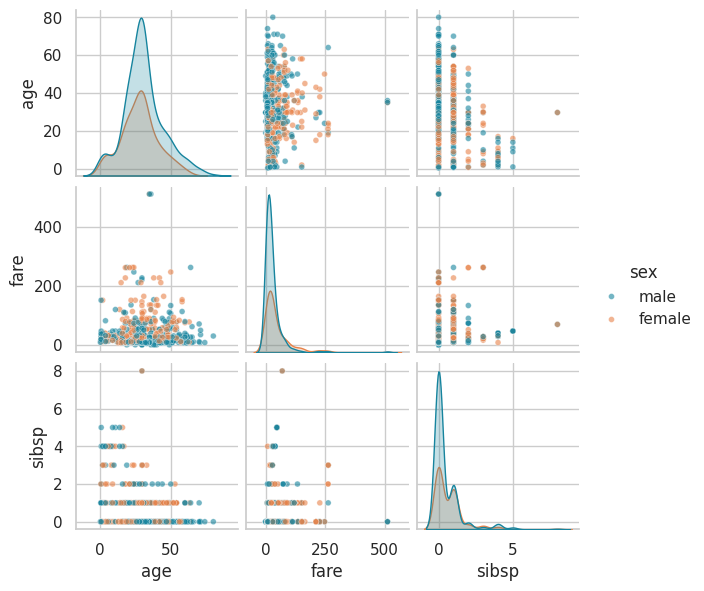

In [ ]:
g = sns.pairplot(
    df[["age", "fare", "sibsp", "sex"]],
    hue="sex",
    palette={"female": "#E8834A", "male": "#16849E"},
    height=2.0,
    plot_kws={"alpha": 0.6, "s": 18}
)
plt.show()

## PERTANYAAN DISKUSI



**1. Mengapa histogram usia memiliki lonjakan di sekitar usia 30?**

* **Penyebab:**
  Lonjakan tajam di sekitar usia 30 tahun terjadi karena keputusan saat pembersihan data (*data cleaning*) di sel awal, di mana nilai yang hilang (*missing values*) pada kolom `age` diisi (*imputed*) menggunakan nilai rata-rata (*mean*) dari keseluruhan data:
  `df["age"] = df["age"].fillna(df["age"].mean())`.
  Karena nilai rata-rata usia penumpang Titanic berada di kisaran ~29.7 tahun, maka ratusan baris data kosong yang semula tidak memiliki nilai kini menumpuk tepat di satu titik nilai rata-rata tersebut.

* **Dampaknya terhadap Interpretasi Distribusi:**

  a. **Artifisial (Palsu):** Pola Buatan (Artifisial): Penumpukan ini murni efek samping dari manipulasi statistik, bukan mencerminkan kondisi demografi penumpang yang sebenarnya. <br>
  b. **Mengecilkan Variabilitas:** Penggunaan nilai rata-rata untuk mengisi banyak data kosong menyebabkan variasi (standar deviasi) mengecil. Persebaran usia menjadi tampak lebih terpusat daripada realitas aslinya. <br>
  c. **Potensi Bias:** Jika data ini langsung dipakai untuk pembuatan model prediktif, model berisiko salah menangkap pola dan menganggap kelompok usia 30 tahun memiliki pengaruh atau dominasi yang jauh lebih besar dari yang seharusnya. <br>

2. Heatmap menunjukkan korelasi fare–pclass sebesar −0,55. Jelaskan arti tanda negatif tersebut,
dan mengapa korelasi tidak boleh langsung disimpulkan sebagai hubungan sebab-akibat.

* **Arti Tanda Negatif (-0.55):**
  Secara statistik, korelasi negatif menunjukkan hubungan yang berbanding terbalik antar dua variabel.
  - Di dalam dataset Titanic, kelas tiket (*pclass*) dinyatakan dengan angka: Kelas 1 (tertinggi), Kelas 2, dan Kelas 3 (terendah).
  - Hubungan negatif sebesar **-0.55** berarti **semakin kecil nilai kelasnya (menuju Kelas 1), maka tarif tiketnya (*fare*) akan cenderung semakin mahal/tinggi**. Sebaliknya, semakin besar angka kelasnya (menuju Kelas 3), harga tiketnya justru semakin murah. Angka 0.55 ini menunjukkan hubungan kebalikan yang cukup kuat/moderat.

* **Mengapa Korelasi Tidak Boleh Langsung Disimpulkan Sebagai Hubungan Sebab-Akibat (Causation)?**
  Sebagai mahasiswa, kita harus kritis bahwa korelasi hanya menunjukkan adanya kecenderungan pola hubungan linear secara matematis, bukan bukti bahwa satu variabel menjadi penyebab langsung dari variabel lainnya. Ada beberapa alasan penting:
  1. **Adanya Variabel Ketiga (*Confounding Variable*):** Hubungan korelasi bisa dipengaruhi oleh faktor lain yang tidak dimasukkan dalam perhitungan linear sederhana. Contohnya, hubungan keselamatan (*survived*) dengan tarif (*fare*) yang bernilai positif (0.24). Ini tidak berarti membayar uang lebih banyak secara ajaib membuat tubuh kebal dari tenggelam. Penyebab aslinya adalah akses prioritas sekoci dan posisi kamar kelas atas yang lebih dekat dengan dek kapal.
  2. **Arah Hubungan yang Belum Tentu Searah:** Korelasi tidak memberi tahu kita variabel mana yang memengaruhi mana secara kronologis.
  3. **Kebetulan Semata (*Spurious Correlation*):** Terkadang dua data bisa terlihat sangat berkorelasi secara matematis hanya karena kebetulan tren waktu atau pengambilan sampel, padahal secara logika tidak memiliki hubungan logis sama sekali.

3. Kapan Anda memilih histogram, boxplot, atau violin plot untuk menggambarkan distribusi? Berikan satu contoh situasi untuk masing-masing.

* **a. Histogram (dan KDE)**
  * **Kapan dipilih:** Ketika kita ingin melihat bentuk distribusi data secara mendetail pada **satu variabel kontinu tunggal**. Histogram sangat bagus untuk mengidentifikasi kesimetrisan data (apakah berdistribusi normal, menjulur ke kanan/kiri), melihat modus tunggal atau ganda (*bimodal/multimodal*), serta mendeteksi celah kosong di rentang data tertentu.
  * **Contoh Situasi:** Analisis awal demografi penumpang untuk melihat konsentrasi kelompok usia penumpang kapal secara keseluruhan (apakah didominasi anak-anak, usia produktif, atau lansia).

* **b. Boxplot**
  * **Kapan dipilih:** Ketika fokus utama kita adalah **membandingkan ringkasan lima angka statistik** (nilai minimum, kuartil bawah/Q1, median/Q2, kuartil atas/Q3, dan nilai maksimum) serta **mengidentifikasi pencilan (*outliers*)** secara bersih di antara beberapa kelompok kategori.
  * **Contoh Situasi:** Membandingkan variasi tarif tiket (*fare*) di antara kelas 1, 2, dan 3 untuk mendeteksi apakah ada penumpang kelas bawah yang membayar tarif sangat tinggi di luar kewajaran (pencilan).

* **c. Violin Plot**
  * **Kapan dipilih:** Ketika kita ingin melakukan perbandingan antarkelompok kategori (seperti *boxplot*), tetapi juga **ingin melihat bentuk kurva kepadatan (*density*) data secara bersamaan**. Grafik ini sangat berguna jika data kita memiliki distribusi multi-puncak (*multimodal*) di dalam kelompok yang tidak akan terlihat jelas jika hanya menggunakan boxplot biasa.
  * **Contoh Situasi:** Membandingkan sebaran usia penumpang laki-laki vs perempuan di setiap kelas tiket (*pclass*) untuk melihat apakah ada pola kepadatan usia ganda (misal: penumpukan balita sekaligus lansia) dalam satu kategori yang sama.